# Federated Transfer Learning Across 5 Heterogeneous Medical Datasets

**Extending the previous 2 client medical experiment.** The earlier Federated Transfer Learning study used
two datasets that were both binary (PneumoniaMNIST and BreastMNIST), so a single shared classification head
could serve both clients. This experiment adds three more medical datasets that are genuinely different in
structure, not just in content:

| Client | Dataset | Classes | Class Count |
|---|---|---|---|
| 1 | PneumoniaMNIST | Normal / Pneumonia | 2 |
| 2 | BreastMNIST | Malignant / Normal, Benign | 2 |
| 3 | DermaMNIST | 7 skin lesion types | 7 |
| 4 | PathMNIST | 9 colon tissue types | 9 |
| 5 | OrganAMNIST | 11 organ types (CT scan) | 11 |

**Why this breaks the previous design, and how this experiment fixes it.** FedAvg, FedProx and FedAdam all
work by averaging weight tensors, which requires every client's classification head to have the exact same
output shape. That was true when every client was solving a 2 class problem. It is no longer true here (2,
2, 7, 9, and 11 classes are all different shapes) - so the *classification head* can no longer be
federated across all five clients.

The fix used in this experiment: keep the **backbone shared and federated**, but give every client a
**personalized classification head** sized to its own number of classes, which is trained purely locally and
never averaged. Specifically:
- Most of the pretrained ResNet-18 backbone stays frozen, exactly as before.
- The **last residual block** (`layer4`) is unfrozen and *is* federated - it has the identical shape on
  every client regardless of how many output classes that client has, so FedAvg / FedProx / FedAdam remain
  valid here.
- Each client's final classification head (`layer4` output -> its own number of classes) is trained locally
  only, and is never sent to the server or averaged with anyone else's head.

This is closer to how federated transfer learning is actually used in practice across genuinely
heterogeneous institutions: everyone shares and improves a common feature extractor, while each site keeps
a model output that matches its own local task.
**A note on runtime:** this config is set to finish in a few minutes on a Colab GPU runtime (T4 is enough).
Before running, check **Runtime > Change runtime type > GPU**, then confirm with:
```python
import torch; print(torch.cuda.is_available())
```
This must print `True`. If it prints `False`, everything below will run on CPU and can take hours instead of
minutes — that is almost certainly what happened if a previous run took around 10 hours. The dataset size
caps and image resolution below have also been reduced from the original version specifically to keep this
fast, at a small cost to final accuracy.


---
## Section 1: Imports & Device Setup

In [1]:
import sys
!{sys.executable} -m pip install -q torch torchvision medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 4.6 MB/s eta 0:00:00


In [2]:
import torch, torch.nn as nn, torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
import torchvision.transforms as transforms
import torchvision.models as models
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

from medmnist import PneumoniaMNIST, BreastMNIST, DermaMNIST, PathMNIST, OrganAMNIST

if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
    DEVICE = torch.device('cpu')

np.random.seed(42); torch.manual_seed(42)
print(f'Device  : {DEVICE}')
print(f'PyTorch : {torch.__version__}')
if DEVICE.type == 'cpu':
    print('WARNING: running on CPU. This will be slow. If on Mac, check that torch.backends.mps.is_available() is True.')


Device  : cuda
PyTorch : 2.11.0+cu128


---
## Section 2: Configuration

In [3]:
CONFIG = {
    'num_rounds'          : 6,
    'local_epochs'        : 2,
    'batch_size'          : 64,
    'learning_rate'       : 0.001,
    'image_size'          : 64,
    'mu_prox'             : 0.01,
    'server_lr'           : 0.1,
    'beta1'               : 0.9,
    'beta2'               : 0.99,
    'tau'                 : 1e-3,
    'max_train_per_client': 800,
}

DATASET_INFO = {
    'PneumoniaMNIST' : {'loader': PneumoniaMNIST, 'num_classes': 2},
    'BreastMNIST'    : {'loader': BreastMNIST,    'num_classes': 2},
    'DermaMNIST'     : {'loader': DermaMNIST,     'num_classes': 7},
    'PathMNIST'      : {'loader': PathMNIST,      'num_classes': 9},
    'OrganAMNIST'    : {'loader': OrganAMNIST,    'num_classes': 11},
}
print('Configuration loaded')
for k, v in CONFIG.items(): print(f'   {k}: {v}')
print('\nClients:')
for name, info in DATASET_INFO.items():
    print(f'   {name}: {info["num_classes"]} classes')


Configuration loaded
   num_rounds: 6
   local_epochs: 2
   batch_size: 64
   learning_rate: 0.001
   image_size: 64
   mu_prox: 0.01
   server_lr: 0.1
   beta1: 0.9
   beta2: 0.99
   tau: 0.001
   max_train_per_client: 800

Clients:
   PneumoniaMNIST: 2 classes
   BreastMNIST: 2 classes
   DermaMNIST: 7 classes
   PathMNIST: 9 classes
   OrganAMNIST: 11 classes


---
## Section 3: Load All 5 Datasets

In [4]:
imagenet_mean, imagenet_std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

transform_train = transforms.Compose([
    transforms.ToPILImage() if False else transforms.Lambda(lambda x: x),
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])
transform_test = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((CONFIG['image_size'], CONFIG['image_size'])),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std),
])

class MedMNISTWrapper(Dataset):
    def __init__(self, medmnist_dataset):
        self.ds = medmnist_dataset
    def __len__(self):
        return len(self.ds)
    def __getitem__(self, i):
        img, label = self.ds[i]
        return img, int(label[0]) if hasattr(label, '__len__') else int(label)

client_names, client_num_classes = [], []
client_train_datasets, client_test_datasets = [], []

for name, info in DATASET_INFO.items():
    LoaderClass = info['loader']
    train_raw = LoaderClass(split='train', transform=transform_train, download=True)
    test_raw  = LoaderClass(split='test',  transform=transform_test,  download=True)
    train_ds  = MedMNISTWrapper(train_raw)
    test_ds   = MedMNISTWrapper(test_raw)

    if len(train_ds) > CONFIG['max_train_per_client']:
        idx = np.random.choice(len(train_ds), CONFIG['max_train_per_client'], replace=False)
        train_ds = Subset(train_ds, idx.tolist())

    client_names.append(name)
    client_num_classes.append(info['num_classes'])
    client_train_datasets.append(train_ds)
    client_test_datasets.append(test_ds)
    print(f'   {name}: {len(train_ds)} train (capped) / {len(test_ds)} test | {info["num_classes"]} classes')

client_sizes   = [len(ds) for ds in client_train_datasets]
client_loaders = [DataLoader(ds, batch_size=CONFIG['batch_size'], shuffle=True) for ds in client_train_datasets]
client_test_loaders = [DataLoader(ds, batch_size=64, shuffle=False) for ds in client_test_datasets]

100%|██████████| 4.17M/4.17M [00:04<00:00, 1.03MB/s]


   PneumoniaMNIST: 800 train (capped) / 624 test | 2 classes


100%|██████████| 560k/560k [00:00<00:00, 694kB/s]


   BreastMNIST: 546 train (capped) / 156 test | 2 classes


100%|██████████| 19.7M/19.7M [00:07<00:00, 2.66MB/s]


   DermaMNIST: 800 train (capped) / 2005 test | 7 classes


100%|██████████| 206M/206M [02:08<00:00, 1.60MB/s]


   PathMNIST: 800 train (capped) / 7180 test | 9 classes


100%|██████████| 38.2M/38.2M [00:13<00:00, 2.91MB/s]


   OrganAMNIST: 800 train (capped) / 17778 test | 11 classes


---
## Section 4: Personalized Transfer Learning Model

In [5]:
class PersonalizedTransferModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        self.stem   = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool,
                                     backbone.layer1, backbone.layer2, backbone.layer3)
        self.layer4 = backbone.layer4
        self.pool   = backbone.avgpool
        for p in self.stem.parameters():
            p.requires_grad = False
        self.head = nn.Sequential(
            nn.Linear(512, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )
    def forward(self, x):
        with torch.no_grad():
            x = self.stem(x)
        x = self.layer4(x)
        x = torch.flatten(self.pool(x), 1)
        return self.head(x)

_probe = PersonalizedTransferModel(num_classes=5)
n_total     = sum(p.numel() for p in _probe.parameters())
n_frozen    = sum(p.numel() for p in _probe.stem.parameters())
n_federated = sum(p.numel() for p in _probe.layer4.parameters())
n_head      = sum(p.numel() for p in _probe.head.parameters())
print(f'Total parameters      : {n_total:,}')
print(f'Frozen (stem)         : {n_frozen:,}  <- never trained, identical on all clients')
print(f'Federated (layer4)    : {n_federated:,}  <- trained locally, averaged by the server every round')
print(f'Personalized (head)   : {n_head:,}  <- trained locally, stays on each client, never shared')
del _probe

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 152MB/s]

Total parameters      : 11,209,669
Frozen (stem)         : 2,782,784  <- never trained, identical on all clients
Federated (layer4)    : 8,393,728  <- trained locally, averaged by the server every round
Personalized (head)   : 33,157  <- trained locally, stays on each client, never shared


---
## Section 5: Helper Functions

In [6]:
def train_local(model, loader, optimizer, epochs, device):
    model.train()
    ce = nn.CrossEntropyLoss()
    for _ in range(epochs):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            ce(model(imgs), labels).backward()
            optimizer.step()

def train_local_fedprox(model, loader, optimizer, epochs, device, global_layer4_state, mu):
    model.train()
    ce = nn.CrossEntropyLoss()
    global_params = {k: v.clone().detach().to(device) for k, v in global_layer4_state.items()}
    for _ in range(epochs):
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = ce(model(imgs), labels)
            prox = sum(((p - global_params[n]) ** 2).sum()
                       for n, p in model.layer4.named_parameters() if n in global_params)
            (loss + (mu / 2) * prox).backward()
            optimizer.step()

def evaluate_model(model, loader, device):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            correct += (model(imgs).argmax(1) == labels).sum().item()
            total   += labels.size(0)
    return correct / total

def weighted_avg_layer4(models_list, sizes):
    total = sum(sizes)
    keys = models_list[0].layer4.state_dict().keys()
    return {k: sum(models_list[i].layer4.state_dict()[k].float() * (sizes[i] / total) for i in range(len(models_list)))
            for k in keys}

print('Helper functions ready')

Helper functions ready


---
## Section 6: Run FedAvg, FedProx, FedAdam (federating only layer4) + a Local-Only Baseline

In [7]:
def run_algo(algo_name, use_prox=False, federate=True):
    label = 'Local Only (no federation)' if not federate else ('FedProx' if use_prox else algo_name.upper())
    print('='*70); print(f'  {label}'); print('='*70)

    clients = [PersonalizedTransferModel(nc).to(DEVICE) for nc in client_num_classes]
    opts    = [optim.Adam(filter(lambda p: p.requires_grad, m.parameters()), lr=CONFIG['learning_rate'])
               for m in clients]
    global_layer4_state = clients[0].layer4.state_dict()
    server_m, server_v = {}, {}
    history = {name: [] for name in client_names}
    history['round'] = []

    for rnd in range(1, CONFIG['num_rounds'] + 1):
        if federate:
            for c in clients:
                c.layer4.load_state_dict(global_layer4_state)

        for c, opt, loader in zip(clients, opts, client_loaders):
            if federate and use_prox:
                train_local_fedprox(c, loader, opt, CONFIG['local_epochs'], DEVICE, global_layer4_state, CONFIG['mu_prox'])
            else:
                train_local(c, loader, opt, CONFIG['local_epochs'], DEVICE)

        if federate:
            avg_layer4 = weighted_avg_layer4(clients, client_sizes)
            if algo_name == 'fedadam':
                beta1, beta2, tau, server_lr = CONFIG['beta1'], CONFIG['beta2'], CONFIG['tau'], CONFIG['server_lr']
                new_layer4 = {}
                for key in avg_layer4:
                    delta = avg_layer4[key].float() - global_layer4_state[key].float()
                    if key not in server_m:
                        server_m[key] = torch.zeros_like(delta)
                        server_v[key] = torch.full_like(delta, tau ** 2)
                    server_m[key] = beta1 * server_m[key] + (1 - beta1) * delta
                    server_v[key] = beta2 * server_v[key] + (1 - beta2) * (delta ** 2)
                    new_layer4[key] = global_layer4_state[key].float() + server_lr * server_m[key] / (torch.sqrt(server_v[key]) + tau)
                global_layer4_state = new_layer4
            else:
                global_layer4_state = avg_layer4

        round_accs = []
        for c, test_loader, name in zip(clients, client_test_loaders, client_names):
            acc = evaluate_model(c, test_loader, DEVICE)
            history[name].append(acc); round_accs.append(acc)
        history['round'].append(rnd)
        acc_str = ' | '.join(f'{n}: {a:.4f}' for n, a in zip(client_names, round_accs))
        print(f'  Round {rnd:02d} | {acc_str}')

    print(f'\nFinal accuracies:')
    for name in client_names:
        print(f'   {name:16s}: {history[name][-1]:.4f}')
    print()
    return history

history_local    = run_algo('local', federate=False)
history_fedavg   = run_algo('fedavg')
history_fedprox  = run_algo('fedavg', use_prox=True)
history_fedadam  = run_algo('fedadam')

  Local Only (no federation)
  Round 01 | PneumoniaMNIST: 0.8141 | BreastMNIST: 0.7436 | DermaMNIST: 0.6853 | PathMNIST: 0.7022 | OrganAMNIST: 0.7967
  Round 02 | PneumoniaMNIST: 0.8526 | BreastMNIST: 0.8141 | DermaMNIST: 0.6778 | PathMNIST: 0.7372 | OrganAMNIST: 0.8284
  Round 03 | PneumoniaMNIST: 0.7997 | BreastMNIST: 0.8013 | DermaMNIST: 0.6828 | PathMNIST: 0.7586 | OrganAMNIST: 0.8437
  Round 04 | PneumoniaMNIST: 0.8269 | BreastMNIST: 0.8269 | DermaMNIST: 0.6778 | PathMNIST: 0.7571 | OrganAMNIST: 0.8378
  Round 05 | PneumoniaMNIST: 0.7901 | BreastMNIST: 0.8462 | DermaMNIST: 0.6643 | PathMNIST: 0.7383 | OrganAMNIST: 0.8297
  Round 06 | PneumoniaMNIST: 0.8109 | BreastMNIST: 0.8654 | DermaMNIST: 0.6693 | PathMNIST: 0.7627 | OrganAMNIST: 0.8175

Final accuracies:
   PneumoniaMNIST  : 0.8109
   BreastMNIST     : 0.8654
   DermaMNIST      : 0.6693
   PathMNIST       : 0.7627
   OrganAMNIST     : 0.8175

  FEDAVG
  Round 01 | PneumoniaMNIST: 0.8013 | BreastMNIST: 0.7564 | DermaMNIST: 0.68

---
## Section 7: Why FedDistillation Is Not Included Here

FedDistillation works by having every client produce predictions over the **same set of classes** on a
shared public sample, which the server then combines into one ensembled teaching signal for one global
model. That assumption breaks down completely in this experiment: Client 1 predicts over 2 classes, Client 3
over 7, Client 4 over 9, and Client 5 over 11 - there is no shared output space to ensemble predictions
into. Forcing a common label space here (the way Experiment 2 mapped CIFAR-10 and STL-10 onto 9 shared
classes) is not medically meaningful for these datasets, since chest X-ray, skin lesion, colon tissue, and
organ CT categories do not correspond to one another.

This is itself a useful finding: **FedDistillation trades away weight-sharing flexibility for a stricter
requirement on shared output classes**, while the layer4-federation approach used above trades away some of
FedDistillation's flexibility for the ability to keep a personalized head per client, regardless of how
different each client's task is. Neither approach is free - each solves a different kind of heterogeneity.

---
## Section 8: Compare Algorithms Per Client

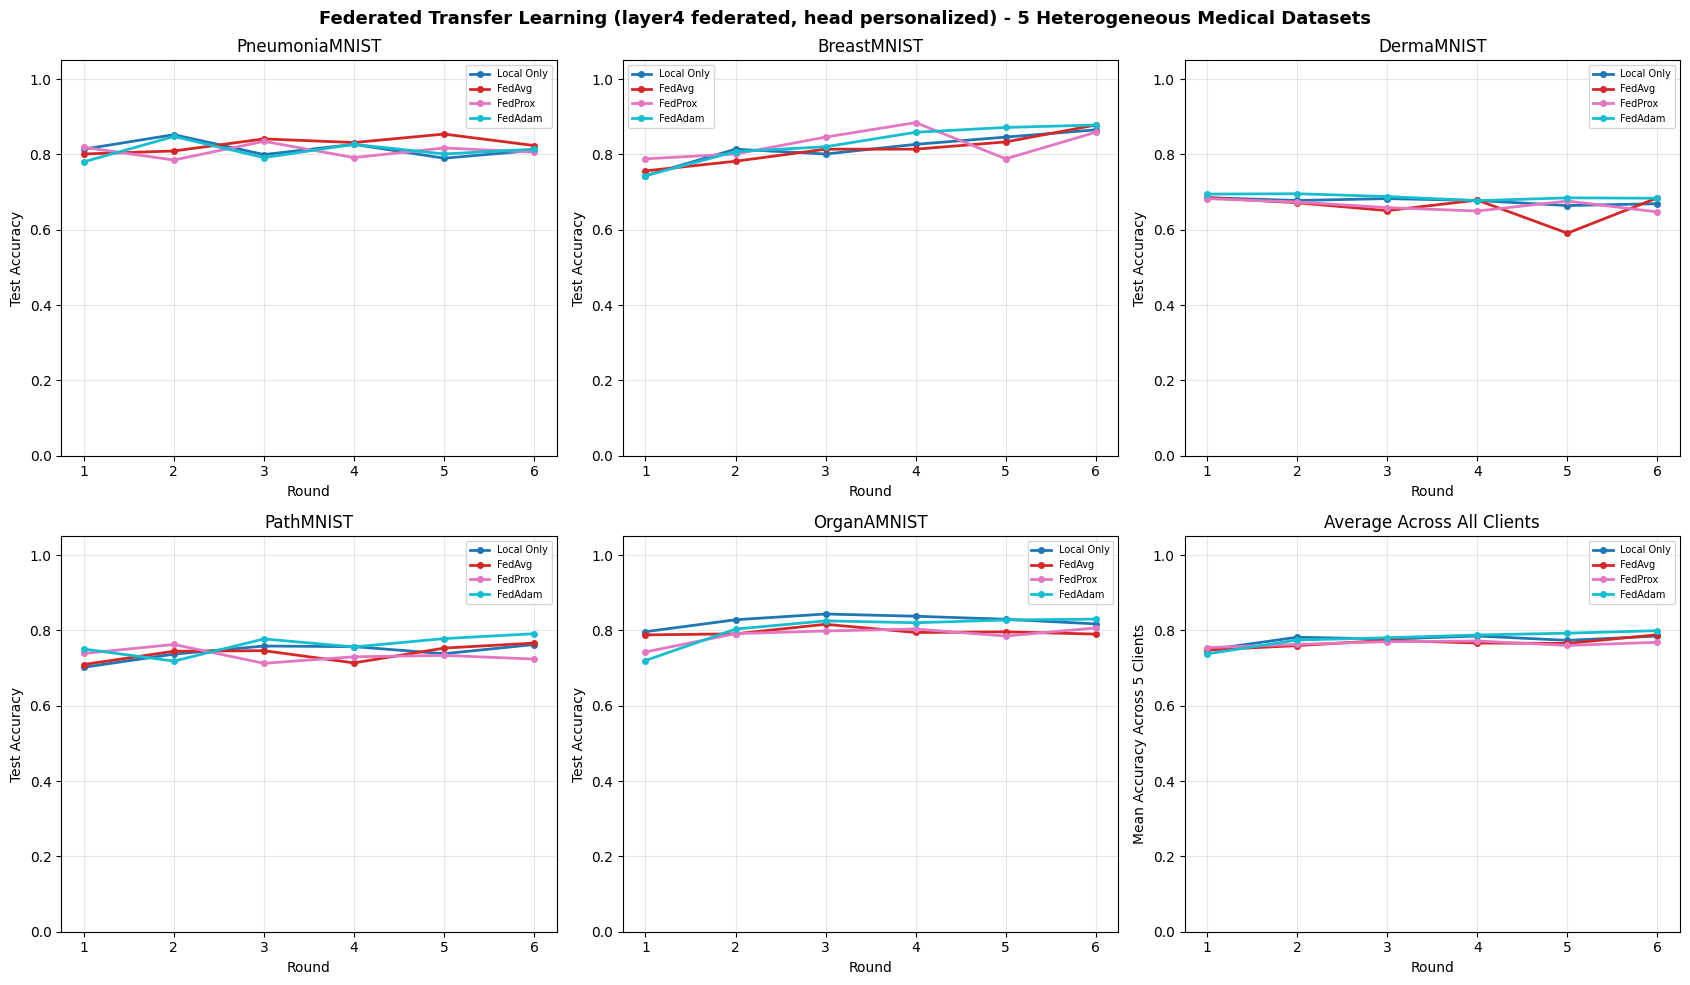

Saved as multi_medical_ftl_comparison.png

Final round accuracy - Algorithm x Client:
Algorithm        | PneumoniaMNIST | BreastMNIST    | DermaMNIST     | PathMNIST      | OrganAMNIST    | Mean
Local Only       |         0.8109 |         0.8654 |         0.6693 |         0.7627 |         0.8175 | 0.7852
FedAvg           |         0.8237 |         0.8782 |         0.6848 |         0.7666 |         0.7904 | 0.7887
FedProx          |         0.8061 |         0.8590 |         0.6474 |         0.7241 |         0.8068 | 0.7687
FedAdam          |         0.8141 |         0.8782 |         0.6838 |         0.7914 |         0.8301 | 0.7995


In [8]:
results = {
    'Local Only' : history_local,
    'FedAvg'     : history_fedavg,
    'FedProx'    : history_fedprox,
    'FedAdam'    : history_fedadam,
}

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
fig.suptitle('Federated Transfer Learning (layer4 federated, head personalized) - 5 Heterogeneous Medical Datasets',
             fontsize=13, fontweight='bold')
axes = axes.flatten()
palette = plt.cm.tab10(np.linspace(0, 1, 4))

for ax, name in zip(axes, client_names):
    for (algo, hist), color in zip(results.items(), palette):
        ax.plot(hist['round'], hist[name], '-o', lw=2, ms=4, color=color, label=algo)
    ax.set(xlabel='Round', ylabel='Test Accuracy', title=name)
    ax.legend(fontsize=7); ax.grid(alpha=0.3); ax.set_ylim(0, 1.05)

avg_by_algo = {algo: [np.mean([hist[name][r] for name in client_names]) for r in range(CONFIG['num_rounds'])]
               for algo, hist in results.items()}
for (algo, avg_hist), color in zip(avg_by_algo.items(), palette):
    axes[5].plot(range(1, CONFIG['num_rounds']+1), avg_hist, '-o', lw=2, ms=4, color=color, label=algo)
axes[5].set(xlabel='Round', ylabel='Mean Accuracy Across 5 Clients', title='Average Across All Clients')
axes[5].legend(fontsize=7); axes[5].grid(alpha=0.3); axes[5].set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig('multi_medical_ftl_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved as multi_medical_ftl_comparison.png')

print('\nFinal round accuracy - Algorithm x Client:')
header = f'{"Algorithm":16s} | ' + ' | '.join(f'{n[:14]:14s}' for n in client_names) + ' | Mean'
print(header); print('=' * len(header))
for algo, hist in results.items():
    row_vals = [hist[name][-1] for name in client_names]
    print(f'{algo:16s} | ' + ' | '.join(f'{v:14.4f}' for v in row_vals) + f' | {np.mean(row_vals):.4f}')

---
## Section 9: Summary

**What changed compared to the earlier 2 client medical experiment:** instead of forcing every client onto
one shared binary head, only the last backbone block (`layer4`) is federated, and every client keeps a
personalized classification head sized to its own task. This lets genuinely incompatible medical tasks (2,
2, 7, 9, and 11 classes) participate in the same federated round without any label remapping.

**What to check in the results above:**
- Does federating `layer4` (FedAvg / FedProx / FedAdam) actually beat the **Local Only** baseline, where each
  client trains completely independently? If yes, the shared feature extractor is transferring useful
  general visual structure across very different medical domains. If federation performs about the same or
  worse than Local Only for a given client, that client may be too different from the others for shared
  `layer4` features to help, and it might be better served training fully locally.
- Which algorithm gives the most *even* improvement across all 5 clients, versus one that mostly helps the
  larger datasets (PathMNIST, OrganAMNIST) at the expense of the smaller ones (BreastMNIST, DermaMNIST)?

**What to tell your professor:**
> *"I extended the federated transfer learning study to 5 medical datasets with genuinely different label
> spaces (2, 2, 7, 9, and 11 classes), which meant I could no longer federate the classification head the
> way I did for the 2 binary datasets. Instead, I federated only the last ResNet block, keeping a
> personalized head per client, and compared FedAvg, FedProx, and FedAdam against a fully local, non
> federated baseline to measure whether federation actually helps each client. I also explain why
> FedDistillation could not be included in this setup: it requires a shared output/label space across
> clients to ensemble predictions, which does not exist here, unlike layer4-level weight federation, which
> only requires matching backbone shapes, not matching task labels."*